In [11]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

In [28]:
df = pd.read_csv('500hits.csv', encoding='latin-1')
df

,PLAYER,YRS,G,AB,R,H,2B,3B,HR,RBI,BB,SO,SB,CS,BA,HOF
0,Ty Cobb,24,3035,11434,2246,4189,724,295,117,726,1249,357,892,178,0.366,1
1,Stan Musial,22,3026,10972,1949,3630,725,177,475,1951,1599,696,78,31,0.331,1
2,Tris Speaker,22,2789,10195,1882,3514,792,222,117,724,1381,220,432,129,0.345,1
3,Derek Jeter,20,2747,11195,1923,3465,544,66,260,1311,1082,1840,358,97,0.310,1
4,Honus Wagner,21,2792,10430,1736,3430,640,252,101,0,963,327,722,15,0.329,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
460,Jim Wynn,15,1920,6653,1105,1665,285,39,291,964,1224,1427,225,101,0.250,0
461,Jorge Posada,17,1829,6092,900,1664,379,10,275,1065,936,1453,20,21,0.273,0
462,Brady Anderson,15,1834,6499,1062,1661,338,67,210,761,960,1190,315,100,0.256,0
463,Cookie Rojas,16,1822,6309,714,1660,254,25,54,593,396,489,74,68,0.263,0


In [29]:
df = df.drop(['PLAYER', 'CS'], axis=1)
x, y = df.iloc[: :-1], df.iloc[:, -1]
x, y

(     YRS     G     AB     R     H   2B   3B   HR   RBI    BB    SO   SB  \
 464   15  1468   5629   785  1660  247   71   61   499   266   471  267   
 463   16  1822   6309   714  1660  254   25   54   593   396   489   74   
 462   15  1834   6499  1062  1661  338   67  210   761   960  1190  315   
 461   17  1829   6092   900  1664  379   10  275  1065   936  1453   20   
 460   15  1920   6653  1105  1665  285   39  291   964  1224  1427  225   
 ..   ...   ...    ...   ...   ...  ...  ...  ...   ...   ...   ...  ...   
 4     21  2792  10430  1736  3430  640  252  101     0   963   327  722   
 3     20  2747  11195  1923  3465  544   66  260  1311  1082  1840  358   
 2     22  2789  10195  1882  3514  792  222  117   724  1381   220  432   
 1     22  3026  10972  1949  3630  725  177  475  1951  1599   696   78   
 0     24  3035  11434  2246  4189  724  295  117   726  1249   357  892   
 
         BA  HOF  
 464  0.295    0  
 463  0.263    0  
 462  0.256    0  
 461  0.27

In [30]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=11)

In [31]:
gnb = GaussianNB()
gnb.fit(x_train, y_train)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09


0.9247311827956989


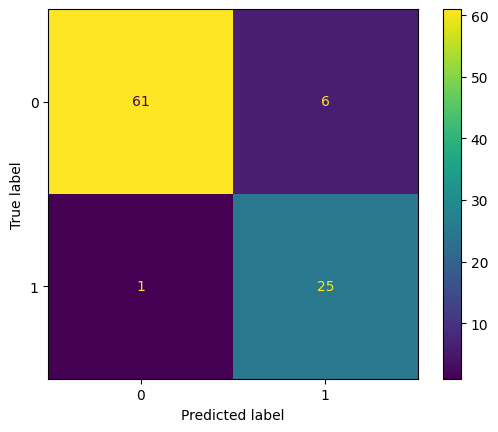

In [32]:
y_pred = gnb.predict(x_test)
print(gnb.score(x_test, y_test))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred)).plot()